In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/all-data.csv
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/License.txt
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/README.txt
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/Sentences_50Agree.txt
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/Sentences_66Agree.txt
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/Sentences_75Agree.txt
/kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/FinancialPhraseBank/Sentences_AllAgree.txt


PyTorch Version: 2.11.0+cpu
Using Device: cpu

Dataset found: /kaggle/input/datasets/ankurzing/sentiment-analysis-for-financial-news/all-data.csv

Dataset loaded successfully!
Total sentences: 4846

Class distribution:
label
neutral     2879
positive    1363
negative     604
Name: count, dtype: int64

Sentence distribution:
Total: 4846
Training: 3392
Validation: 727
Testing: 727

Tokenized input sequences:
['asian', 'traffic', 'declined', 'by', 'per', 'cent']
['net', 'sales', 'surged', 'by', 'percent', 'to', 'eur', 'million']
['finnish', 'media', 'group', 'talentum', 'has', 'issued', 'a', 'profit', 'warning']
['the', 'original', 'contract', 'was', 'signed', 'last', 'summer']
['operating', 'profit', 'rose', 'to', 'eur', 'mn', 'from', 'eur', 'mn']

Vocabulary size: 7625
First 20 vocabulary entries:
[('<pad>', 0), ('<unk>', 1), ('the', 2), ('of', 3), ('in', 4), ('and', 5), ('to', 6), ('a', 7), ('eur', 8), ('s', 9), ('for', 10), ('is', 11), ('will', 12), ('company', 13), ('from', 14), ('on

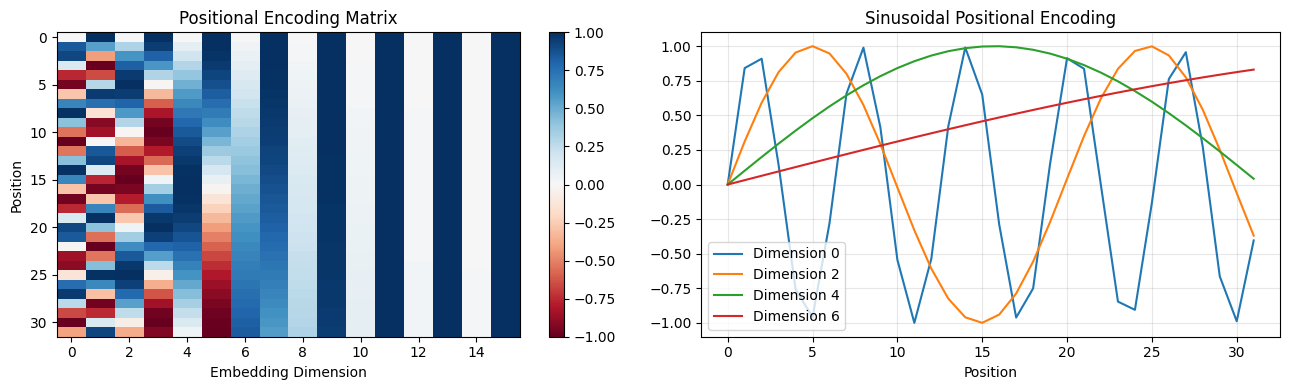


Maximum difference compared with PyTorch MHA: 0.0

Training tensor shape: (3392, 32)
Validation tensor shape: (727, 32)
Testing tensor shape: (727, 32)

Starting model training...

Epoch  1 | Train Accuracy: 0.5938 | Validation Accuracy: 0.5942
Epoch  2 | Train Accuracy: 0.5943 | Validation Accuracy: 0.5942
Epoch  3 | Train Accuracy: 0.6064 | Validation Accuracy: 0.6052
Epoch  4 | Train Accuracy: 0.6397 | Validation Accuracy: 0.6410
Epoch  5 | Train Accuracy: 0.6521 | Validation Accuracy: 0.6410
Epoch  6 | Train Accuracy: 0.6686 | Validation Accuracy: 0.6492
Epoch  7 | Train Accuracy: 0.6851 | Validation Accuracy: 0.6630
Epoch  8 | Train Accuracy: 0.7117 | Validation Accuracy: 0.6589
Epoch  9 | Train Accuracy: 0.7356 | Validation Accuracy: 0.6657
Epoch 10 | Train Accuracy: 0.7529 | Validation Accuracy: 0.6671
Epoch 11 | Train Accuracy: 0.7759 | Validation Accuracy: 0.6685
Epoch 12 | Train Accuracy: 0.7978 | Validation Accuracy: 0.6644

Best Validation Accuracy: 0.6685
Final Test Accur

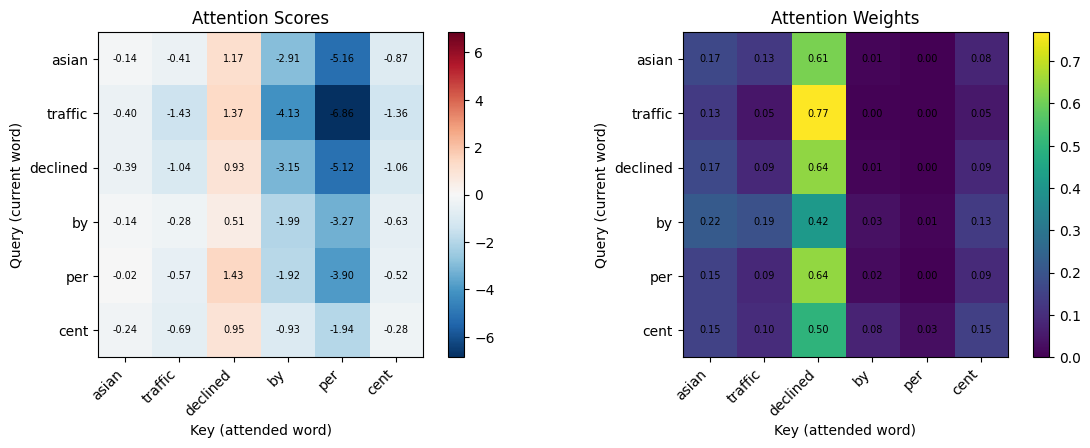

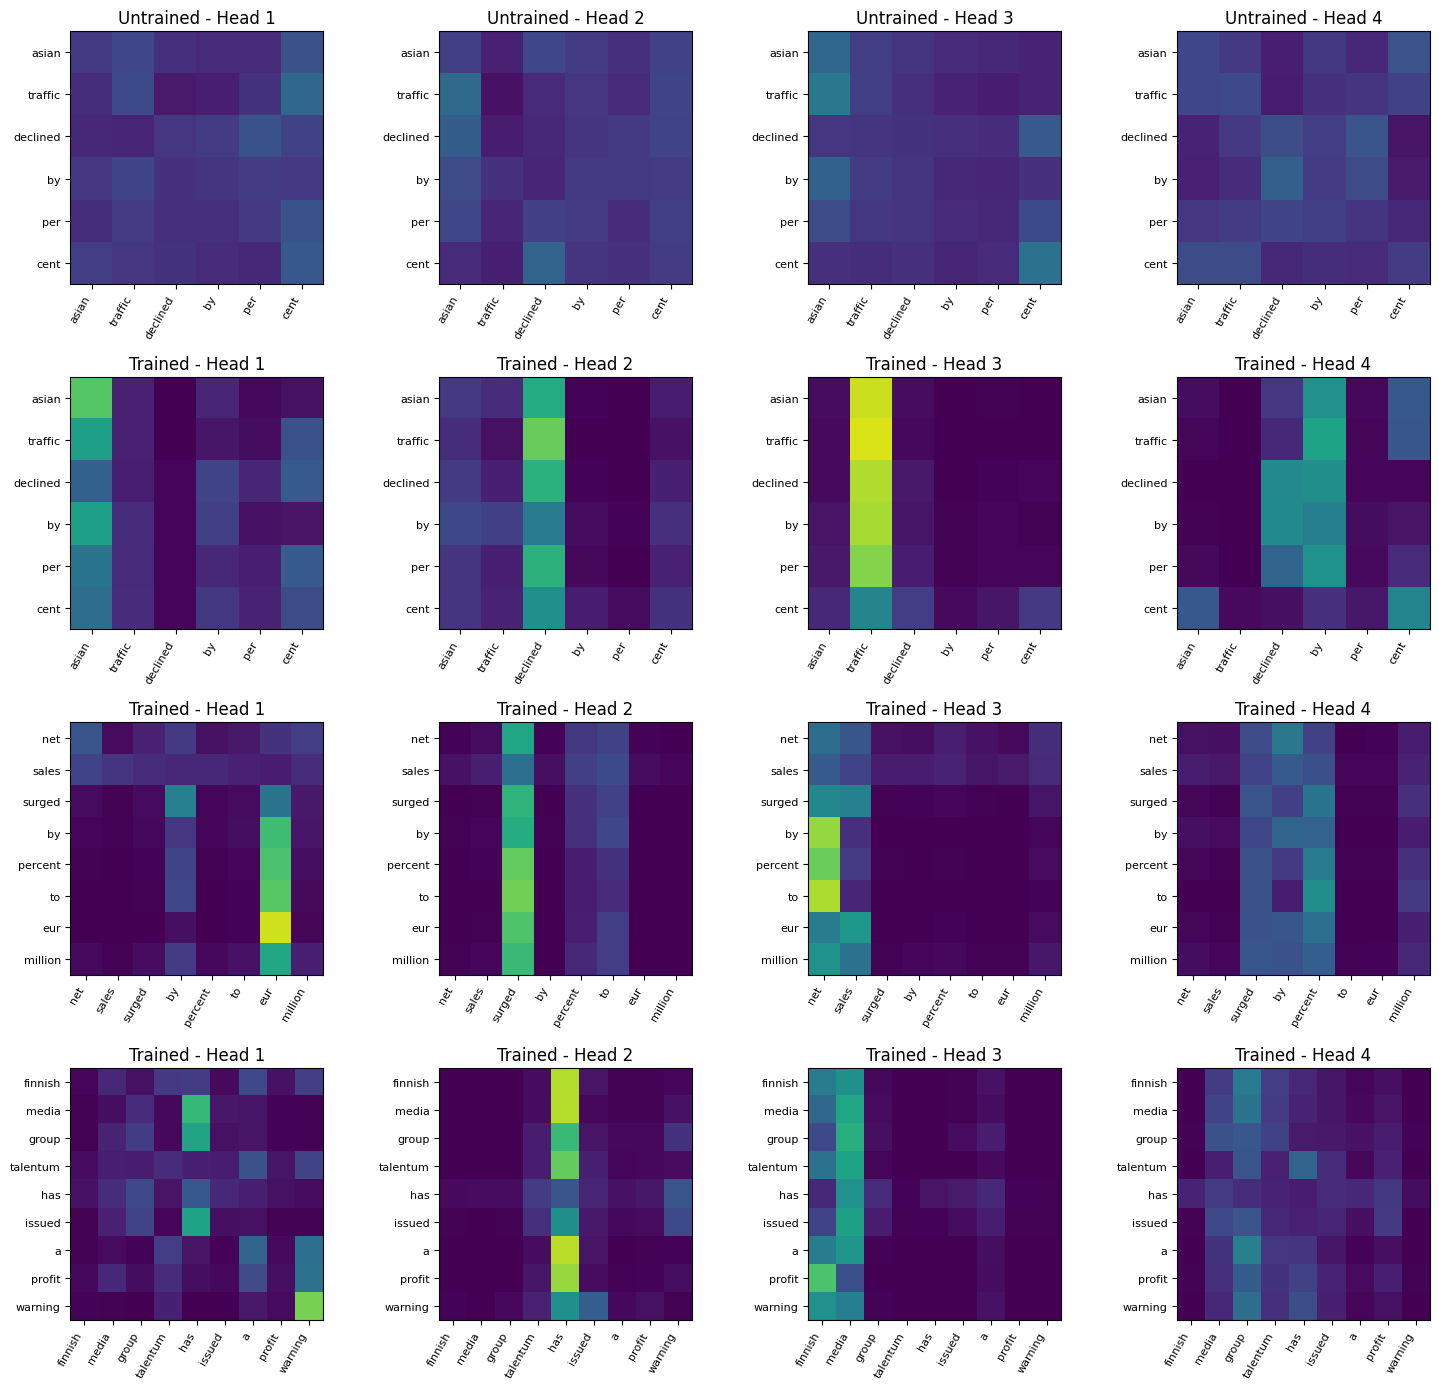


MOST ATTENDED WORD PER HEAD

Asian traffic declined by 3.4 per cent.
Head 1: asian (0.487)
Head 2: declined (0.597)
Head 3: traffic (0.814)
Head 4: by (0.444)

Net sales surged by 30 percent to EUR 36 million.
Head 1: eur (0.536)
Head 2: surged (0.647)
Head 3: net (0.568)
Head 4: percent (0.339)

Finnish media group Talentum has issued a profit warning.
Head 1: has (0.273)
Head 2: has (0.691)
Head 3: media (0.509)
Head 4: group (0.310)

The original contract was signed last summer.
Head 1: signed (0.440)
Head 2: last (0.759)
Head 3: was (0.770)
Head 4: signed (0.911)

Operating profit rose to EUR 4.7 mn from EUR 3.6 mn.
Head 1: eur (0.418)
Head 2: to (0.846)
Head 3: rose (0.598)
Head 4: operating (0.305)

AVERAGE ATTENTION ENTROPY
Uniform: 2.0423
Untrained: 1.9575
Trained: 1.0871

Lower entropy indicates attention concentrated on fewer words.

EFFECT OF POSITIONAL ENCODING
Sentence A: profit rose and sales fell
Sentence B: sales fell and profit rose

Change in attention from 'profit' 

In [2]:


import os
import re
import math
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from collections import Counter
from sklearn.model_selection import train_test_split

# -------------------- 1. CONFIGURATION --------------------

SEED = 42
MAX_LEN = 32
D_MODEL = 16
N_HEADS = 4
EPOCHS = 12
BATCH_SIZE = 64
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version:", torch.__version__)
print("Using Device:", DEVICE)

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.3f}'.format)


# -------------------- 2. LOAD DATASET --------------------

# Automatically locate all-data.csv inside Kaggle input folders.
csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

dataset_path = None

for file in csv_files:
    if os.path.basename(file).lower() == 'all-data.csv':
        dataset_path = file
        break

if dataset_path is None:
    raise FileNotFoundError(
        "all-data.csv was not found!\n"
        "Please attach the Financial News Sentiment dataset using "
        "Kaggle's Add Input option."
    )

print("\nDataset found:", dataset_path)

df = pd.read_csv(
    dataset_path,
    encoding='latin-1',
    header=None,
    names=['label', 'text']
)

# Clean and normalize labels.
df['label'] = df['label'].astype(str).str.strip().str.lower()
classes = ['negative', 'neutral', 'positive']

df = df[df['label'].isin(classes)].copy()
df['text'] = df['text'].fillna('').astype(str)
df['y'] = df['label'].map({
    'negative': 0,
    'neutral': 1,
    'positive': 2
})

df = df[df['text'].str.strip() != ''].reset_index(drop=True)

print("\nDataset loaded successfully!")
print("Total sentences:", len(df))
print("\nClass distribution:")
print(df['label'].value_counts())


# -------------------- 3. TOKENIZATION --------------------

def tokenize(text):
    # Convert to lowercase and retain alphabetic words.
    # Stop words are retained because attention uses sentence context.
    return re.findall(r'[a-z]+', str(text).lower())


df['tokens'] = df['text'].apply(tokenize)

# Remove sentences that become empty after tokenization.
df = df[df['tokens'].map(len) > 0].reset_index(drop=True)

# Split into training, validation and testing sets.
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df['y'],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df['y'],
    random_state=SEED
)

print("\nSentence distribution:")
print("Total:", len(df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

samples = [
    "Asian traffic declined by 3.4 per cent.",
    "Net sales surged by 30 percent to EUR 36 million.",
    "Finnish media group Talentum has issued a profit warning.",
    "The original contract was signed last summer.",
    "Operating profit rose to EUR 4.7 mn from EUR 3.6 mn."
]

print("\nTokenized input sequences:")
for sentence in samples:
    print(tokenize(sentence))


# -------------------- 4. BUILD VOCABULARY --------------------

# Build vocabulary using only training data.
counts = Counter(
    word
    for tokens in train_df['tokens']
    for word in tokens
)

vocab = ['<pad>', '<unk>'] + [
    word for word, _ in counts.most_common()
]

word2idx = {word: idx for idx, word in enumerate(vocab)}
V = len(vocab)

def encode(tokens):
    ids = [word2idx.get(word, 1) for word in tokens]
    ids = ids[:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

print("\nVocabulary size:", V)
print("First 20 vocabulary entries:")
print(list(word2idx.items())[:20])

print("\nToken to index:")
for sentence in samples:
    tokens = tokenize(sentence)
    print(tokens)
    print([word2idx.get(word, 1) for word in tokens])


# -------------------- 5. POSITIONAL ENCODING --------------------

def positional_encoding(max_len, d_model):
    pe = torch.zeros(max_len, d_model)

    position = torch.arange(max_len).unsqueeze(1).float()
    i2 = torch.arange(0, d_model, 2).float()

    angle = position / torch.pow(10000, i2 / d_model)

    pe[:, 0::2] = torch.sin(angle)
    pe[:, 1::2] = torch.cos(angle)

    return pe


PE = positional_encoding(MAX_LEN, D_MODEL)

print("\nPositional Encoding Matrix Shape:", tuple(PE.shape))
print("\nFirst 8 positions:")

print(pd.DataFrame(
    PE[:8].numpy(),
    index=[f'pos {p}' for p in range(8)],
    columns=[f'd{j}' for j in range(D_MODEL)]
))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

im = ax[0].imshow(
    PE.numpy(),
    cmap='RdBu',
    aspect='auto',
    vmin=-1,
    vmax=1
)

ax[0].set_xlabel('Embedding Dimension')
ax[0].set_ylabel('Position')
ax[0].set_title('Positional Encoding Matrix')
fig.colorbar(im, ax=ax[0])

for j in [0, 2, 4, 6]:
    ax[1].plot(PE[:, j].numpy(), label=f'Dimension {j}')

ax[1].set_xlabel('Position')
ax[1].set_title('Sinusoidal Positional Encoding')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('pe.png', dpi=150)
plt.show()


# -------------------- 6. SCALED DOT-PRODUCT ATTENTION --------------------

def scaled_dot_product_attention(Q, K, V, mask=None):

    d_k = Q.size(-1)

    # Calculate attention scores.
    scores = torch.matmul(
        Q,
        K.transpose(-2, -1)
    ) / math.sqrt(d_k)

    # Ignore padding tokens.
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))

    # Convert scores into attention probabilities.
    weights = F.softmax(scores, dim=-1)

    # Calculate context vectors.
    context = torch.matmul(weights, V)

    return context, scores, weights


# -------------------- 7. MULTI-HEAD ATTENTION --------------------

class MultiHeadAttention(nn.Module):

    def __init__(self, d_model, n_heads):
        super().__init__()

        assert d_model % n_heads == 0

        self.h = n_heads
        self.d_k = d_model // n_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.cache = None

    def split_heads(self, x):
        B, L, _ = x.shape

        return x.view(
            B, L, self.h, self.d_k
        ).transpose(1, 2)

    def forward(self, x, pad_mask=None):

        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        Qh = self.split_heads(Q)
        Kh = self.split_heads(K)
        Vh = self.split_heads(V)

        mask = None

        if pad_mask is not None:
            mask = pad_mask[:, None, None, :]

        context, scores, weights = scaled_dot_product_attention(
            Qh, Kh, Vh, mask
        )

        B, _, L, _ = context.shape

        # Concatenate attention heads.
        concat = context.transpose(1, 2).reshape(
            B, L, self.h * self.d_k
        )

        # Final linear projection.
        out = self.W_o(concat)

        self.cache = {
            'Q': Q,
            'K': K,
            'V': V,
            'Qh': Qh,
            'Kh': Kh,
            'Vh': Vh,
            'scores': scores,
            'weights': weights,
            'context': context,
            'concat': concat
        }

        return out, weights


# -------------------- 8. VERIFY WITH PYTORCH MHA --------------------

mha = MultiHeadAttention(D_MODEL, N_HEADS).to(DEVICE)

ref = nn.MultiheadAttention(
    D_MODEL,
    N_HEADS,
    batch_first=True
).to(DEVICE)

with torch.no_grad():

    ref.in_proj_weight.copy_(
        torch.cat([
            mha.W_q.weight,
            mha.W_k.weight,
            mha.W_v.weight
        ])
    )

    ref.in_proj_bias.copy_(
        torch.cat([
            mha.W_q.bias,
            mha.W_k.bias,
            mha.W_v.bias
        ])
    )

    ref.out_proj.weight.copy_(mha.W_o.weight)
    ref.out_proj.bias.copy_(mha.W_o.bias)

x = torch.randn(2, 6, D_MODEL, device=DEVICE)

ours, _ = mha(x)
theirs, _ = ref(x, x, x)

print(
    "\nMaximum difference compared with PyTorch MHA:",
    (ours - theirs).abs().max().item()
)


# -------------------- 9. ATTENTION CLASSIFIER --------------------

class AttentionClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            V,
            D_MODEL,
            padding_idx=0
        )

        self.register_buffer(
            'pe',
            positional_encoding(MAX_LEN, D_MODEL)
        )

        self.mha = MultiHeadAttention(D_MODEL, N_HEADS)

        self.norm = nn.LayerNorm(D_MODEL)

        self.fc = nn.Linear(D_MODEL, len(classes))

    def forward(self, ids):

        pad_mask = (ids != 0)

        # Word embedding + positional encoding.
        x = self.embedding(ids) + self.pe[:ids.size(1)]

        # Multi-head self-attention.
        attn_out, weights = self.mha(x, pad_mask)

        # Residual connection and normalization.
        h = self.norm(x + attn_out)

        # Mean pooling over non-padding tokens.
        mask = pad_mask.unsqueeze(-1).float()

        pooled = (h * mask).sum(1) / mask.sum(1).clamp(min=1)

        output = self.fc(pooled)

        return output, weights


# Convert data into PyTorch tensors.
def convert_to_tensors(data):

    X = torch.tensor(
        data['tokens'].apply(encode).tolist(),
        dtype=torch.long
    )

    y = torch.tensor(
        data['y'].values,
        dtype=torch.long
    )

    return X.to(DEVICE), y.to(DEVICE)


X_tr, y_tr = convert_to_tensors(train_df)
X_va, y_va = convert_to_tensors(val_df)
X_te, y_te = convert_to_tensors(test_df)

print("\nTraining tensor shape:", tuple(X_tr.shape))
print("Validation tensor shape:", tuple(X_va.shape))
print("Testing tensor shape:", tuple(X_te.shape))


# -------------------- 10. TRAINING --------------------

torch.manual_seed(SEED)

model = AttentionClassifier().to(DEVICE)

# Preserve an untrained copy for comparison.
untrained = AttentionClassifier().to(DEVICE)
untrained.load_state_dict(model.state_dict())
untrained.eval()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

def accuracy(m, X, y):

    with torch.no_grad():
        predictions = m(X)[0].argmax(1)

    return (predictions == y).float().mean().item()


best_val = 0
best_state = None

print("\nStarting model training...\n")

for epoch in range(1, EPOCHS + 1):

    model.train()

    permutation = torch.randperm(len(X_tr), device=DEVICE)

    for start in range(0, len(permutation), BATCH_SIZE):

        indices = permutation[start:start + BATCH_SIZE]

        batch_x = X_tr[indices]
        batch_y = y_tr[indices]

        outputs, _ = model(batch_x)

        loss = F.cross_entropy(outputs, batch_y)

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

    model.eval()

    tr_acc = accuracy(model, X_tr, y_tr)
    va_acc = accuracy(model, X_va, y_va)

    print(
        f"Epoch {epoch:2d} | "
        f"Train Accuracy: {tr_acc:.4f} | "
        f"Validation Accuracy: {va_acc:.4f}"
    )

    if va_acc > best_val:
        best_val = va_acc
        best_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }

if best_state is not None:
    model.load_state_dict(best_state)

model.eval()

test_acc = accuracy(model, X_te, y_te)

print("\nBest Validation Accuracy:", round(best_val, 4))
print("Final Test Accuracy:", round(test_acc, 4))


# -------------------- 11. STEP-BY-STEP SENTENCE WALKTHROUGH --------------------

sentence = samples[0]
tokens = tokenize(sentence)
L = len(tokens)

ids = torch.tensor(
    [[word2idx.get(w, 1) for w in tokens]],
    dtype=torch.long,
    device=DEVICE
)

def show(t, cols=None, prefix='d'):

    values = t.detach().cpu().numpy()

    if cols is None:
        cols = [f'{prefix}{j}' for j in range(values.shape[-1])]

    return pd.DataFrame(
        values,
        index=tokens,
        columns=cols
    )


print("\nSENTENCE WALKTHROUGH")
print("Sentence:", sentence)
print("Tokens:", tokens)
print("Indices:", ids[0].tolist())

with torch.no_grad():

    emb = model.embedding(ids)[0]
    x = emb + model.pe[:L]

print("\nToken Embeddings:")
print(show(emb))

print("\nPositional Encoding:")
print(show(model.pe[:L]))

print("\nInput to Attention = Embedding + Positional Encoding:")
print(show(x))

with torch.no_grad():
    out, _ = model.mha(x.unsqueeze(0))

c = model.mha.cache

print("\nQuery Matrix Q = X W_q:")
print(show(c['Q'][0]))

print("\nKey Matrix K = X W_k:")
print(show(c['K'][0]))

print("\nValue Matrix V = X W_v:")
print(show(c['V'][0]))

h = 1
d_k = model.mha.d_k

print(f"\nHead {h+1}: Q, K, V split into {N_HEADS} heads")
print("Dimension per head:", d_k)

print(f"\nQ for Head {h+1}:")
print(show(c['Qh'][0, h], prefix='q'))

print(f"\nK for Head {h+1}:")
print(show(c['Kh'][0, h], prefix='k'))

print(f"\nAttention Scores for Head {h+1}:")
print(show(c['scores'][0, h], cols=tokens))

print(f"\nAttention Weights for Head {h+1}:")
print(show(c['weights'][0, h], cols=tokens))

print("\nAttention Weight Row Sums:")
print(c['weights'][0, h].sum(-1).detach().cpu().numpy().round(3))

print(f"\nContext Vectors for Head {h+1}:")
print(show(c['context'][0, h], prefix='c'))

print("\nConcatenated Attention Heads:")
print(show(c['concat'][0]))

print("\nFinal Multi-Head Attention Output:")
print(show(out[0]))

print("\nOutput Shape:", tuple(out.shape))


# -------------------- 12. ATTENTION HEATMAPS --------------------

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

for a, key, title, cmap in [
    (ax[0], 'scores', 'Attention Scores', 'RdBu_r'),
    (ax[1], 'weights', 'Attention Weights', 'viridis')
]:

    matrix = c[key][0, h].detach().cpu().numpy()

    limit = np.abs(matrix).max()

    im = a.imshow(
        matrix,
        cmap=cmap,
        vmin=-limit if key == 'scores' else 0,
        vmax=limit
    )

    a.set_xticks(range(L))
    a.set_xticklabels(tokens, rotation=45, ha='right')

    a.set_yticks(range(L))
    a.set_yticklabels(tokens)

    a.set_xlabel('Key (attended word)')
    a.set_ylabel('Query (current word)')
    a.set_title(title)

    for i in range(L):
        for j in range(L):
            a.text(
                j, i,
                f'{matrix[i, j]:.2f}',
                ha='center',
                va='center',
                fontsize=7
            )

    fig.colorbar(im, ax=a)

plt.tight_layout()
plt.savefig('scores_weights.png', dpi=150)
plt.show()


# -------------------- 13. COMPARE ATTENTION HEADS --------------------

def get_weights(m, sentence):

    t = tokenize(sentence)

    input_ids = torch.tensor(
        [[word2idx.get(word, 1) for word in t]],
        dtype=torch.long,
        device=DEVICE
    )

    with torch.no_grad():
        _, weights = m(input_ids)

    return t, weights[0].detach().cpu().numpy()


rows = [
    ('Untrained', untrained, samples[0]),
    ('Trained', model, samples[0]),
    ('Trained', model, samples[1]),
    ('Trained', model, samples[2])
]

fig, ax = plt.subplots(
    len(rows),
    N_HEADS,
    figsize=(15, 3.5 * len(rows))
)

for r, (tag, m, sentence) in enumerate(rows):

    t, weights = get_weights(m, sentence)

    for hh in range(N_HEADS):

        a = ax[r, hh]

        a.imshow(
            weights[hh],
            cmap='viridis',
            vmin=0,
            vmax=1
        )

        a.set_xticks(range(len(t)))
        a.set_xticklabels(
            t,
            rotation=60,
            ha='right',
            fontsize=8
        )

        a.set_yticks(range(len(t)))
        a.set_yticklabels(t, fontsize=8)

        a.set_title(f'{tag} - Head {hh+1}')

plt.tight_layout()
plt.savefig('heads.png', dpi=130)
plt.show()


# -------------------- 14. INTERPRETATION --------------------

def entropy(weights):

    weights = np.clip(weights, 1e-9, 1)

    return float(
        -(weights * np.log(weights)).sum(-1).mean()
    )


print("\nMOST ATTENDED WORD PER HEAD\n")

for sentence in samples:

    t, weights = get_weights(model, sentence)

    # Average attention received by each word.
    received = weights.mean(axis=1)

    print(sentence)

    for hh in range(N_HEADS):

        j = received[hh].argmax()

        print(
            f"Head {hh+1}: {t[j]} "
            f"({received[hh, j]:.3f})"
        )

    print()


# Compare attention entropy.
ent_u = np.mean([
    entropy(get_weights(untrained, s)[1])
    for s in samples
])

ent_t = np.mean([
    entropy(get_weights(model, s)[1])
    for s in samples
])

uniform = np.mean([
    np.log(len(tokenize(s)))
    for s in samples
])

print("AVERAGE ATTENTION ENTROPY")
print("Uniform:", round(uniform, 4))
print("Untrained:", round(ent_u, 4))
print("Trained:", round(ent_t, 4))

print("\nLower entropy indicates attention concentrated on fewer words.")


# -------------------- 15. EFFECT OF POSITIONAL ENCODING --------------------

no_pe = AttentionClassifier().to(DEVICE)
no_pe.load_state_dict(model.state_dict())

# Remove positional encoding.
no_pe.pe.zero_()
no_pe.eval()

a_s = 'profit rose and sales fell'
b_s = 'sales fell and profit rose'

print("\nEFFECT OF POSITIONAL ENCODING")

print("Sentence A:", a_s)
print("Sentence B:", b_s)

print("\nChange in attention from 'profit' to each word:")

for name, m in [
    ('With PE', model),
    ('Without PE', no_pe)
]:

    (ta, wa) = get_weights(m, a_s)
    (tb, wb) = get_weights(m, b_s)

    differences = []

    for hh in range(N_HEADS):

        att_a = dict(
            zip(ta, wa[hh][ta.index('profit')])
        )

        att_b = dict(
            zip(tb, wb[hh][tb.index('profit')])
        )

        diff = max(
            abs(att_a[word] - att_b[word])
            for word in att_a
        )

        differences.append(diff)

    print(
        name + ": " +
        " | ".join(
            f"Head {hh+1}: {d:.4f}"
            for hh, d in enumerate(differences)
        )
    )


# Final attention distribution for the word "profit".
t, weights = get_weights(model, a_s)

print(
    f"\nHead {h+1} attention from 'profit' in Sentence A:"
)

profit_attention = {
    word: round(float(value), 3)
    for word, value in zip(
        t,
        weights[h][t.index('profit')]
    )
}

print(profit_attention)


# -------------------- 16. FINAL SUMMARY --------------------

print("\n" + "=" * 60)
print("EXPERIMENT 8 COMPLETED SUCCESSFULLY")
print("=" * 60)

print("Dataset:", os.path.basename(dataset_path))
print("Vocabulary Size:", V)
print("Embedding Dimension:", D_MODEL)
print("Number of Attention Heads:", N_HEADS)
print("Epochs:", EPOCHS)
print("Best Validation Accuracy:", round(best_val, 4))
print("Test Accuracy:", round(test_acc, 4))

print("\nGenerated output files:")
print("1. pe.png - Positional Encoding")
print("2. scores_weights.png - Attention Scores and Weights")
print("3. heads.png - Comparison of Attention Heads")


